In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
import numpy as np
import matplotlib
import seaborn as sns
import matplotlib.patches as mpatches
import json
import sys
import os

from matplotlib import pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from pesummary.io import read
from pesummary.core.plots.bounded_1d_kde import bounded_1d_kde as Bounded_1d_kde
from jinja2 import Template
from corner import hist2d

sys.path.append("./aux_data")
import utils_o3b

matplotlib.rcParams.update(matplotlib.rcParamsDefault)

matplotlib.style.use("paper.style")
plt.rcParams['font.sans-serif'] = [ 'Helvetica', 'Nimbus Sans', 'FreeSans' ]
plt.rcParams['font.serif'] = [ 'Times', 'Nimbus Roman', 'FreeSerif' ]
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'stix'

sns.set_context("paper", font_scale=2.5, rc={"axes.labelsize":40})

In [4]:
# A list of events, review pages:
# https://git.ligo.org/aei-tgr/pseob-higher-modes/-/wikis/O4a-events
# https://git.ligo.org/aei-tgr/pseob-higher-modes/-/wikis/O4b-events
event_list = [
    "GW150914",
    "GW170104",
    "S190519bj",
    "S190521r",
    "S190630ag",
    "S190828j",
    "S190910s",
    "S200129m",
    "S200224ca",
    "S200311bg",
    "S230628ax",
    "S230914ak",
    "S230927be",
    "S231028bg",
    "S231102w",
    "S231206cc",
    "S231226av",
    "GW240511_031507",
    "GW240514_121713",
    "GW240615_113620",
    "GW240621_195059",
    "GW240705_053215",
    "GW240716_034900",
    "GW240919_061559",
    "GW240920_124024",
    "GW241006_015333",
    "GW241127_061008",
    "GW241129_021832",
    "GW241225_082815",
    "GW250114_082203",
    "GW250119_025138",
]

In [5]:
# median (detector-frame) total mass produced with:
# https://git.ligo.org/leonardo.grimaldi/o4b-pseobnr-events/-/blob/main/scripts_O4b_macros_figures/aux_data/dict_det_masses.ipynb?ref_type=heads

mtotal_dict = json.load(open("./aux_data/dict_det_masses.json"))

cmap = plt.cm.coolwarm
norm = matplotlib.colors.TwoSlopeNorm(
    vcenter=100.0, vmin=40.0, vmax=160.0
)

alpha = 0.2

# Prior used for each event
# All the events use a prior on both domega220 and dtau220: [-0.8,2.0]
prior_dict = {
    "dtau_220-min": dict(zip(event_list, -0.8 * np.ones(len(event_list)))),
    "dtau_220-max": dict(zip(event_list, 2.0 * np.ones(len(event_list)))),
    "domega_220-min": dict(zip(event_list, -0.8 * np.ones(len(event_list)))),
    "domega_220-max": dict(zip(event_list, 2.0 * np.ones(len(event_list)))),
}

# Parameters to be visualized
params = ["domega220", "dtau220"]

In [6]:
event_map = {
    "GW150914": "GW150914_095045",
    "GW170104": "GW170104_101158",
    "S190519bj": "GW190519_153544",
    "S190521r": "GW190521_074359",
    "S190630ag": "GW190630_185205",
    "S190828j": "GW190828_063405",
    "S190910s": "GW190910_112807",
    "S200129m": "GW200129_065458",
    "S200224ca": "GW200224_222234",
    "S200311bg": "GW200311_115853",
    "S230628ax": "GW230628_231200",
    "S230914ak": "GW230914_111401",
    "S230927be": "GW230927_153832",
    "S231028bg": "GW231028_153006",
    "S231102w": "GW231102_071736",
    "S231206cc": "GW231206_233901",
    "S231226av": "GW231226_101520",
    "GW240511_031507": "GW240511_031507",
    "GW240514_121713": "GW240514_121713",
    "GW240615_113620": "GW240615_113620",
    "GW240621_195059": "GW240621_195059",
    "GW240705_053215": "GW240705_053215",
    "GW240716_034900": "GW240716_034900",
    "GW240919_061559": "GW240919_061559",
    "GW240920_124024": "GW240920_124024",
    "GW241006_015333": "GW241006_015333",
    "GW241127_061008": "GW241127_061008",
    "GW241129_021832": "GW241129_021832",
    "GW241225_082815": "GW241225_082815",
    "GW250114_082203": "GW250114_082203",
    "GW250119_025138": "GW250119_025138",
}

In [7]:
# Update this path to point to files downloaded from the Zenodo data release
basedir = "/home/leonardo.grimaldi/O4b/data_release/metafiles"

res_dict = dict()

for event in event_map.keys():
    result = read(f"{basedir}/pSEOB_{event_map[event]}_Prod0.h5")
    res_dict[event] = result

lal.MSUN_SI != Msun
__name__ = gwsurrogate.new.spline_evaluation
__package__= gwsurrogate.new


In [8]:
# Load samples first
sample_dict = {}

for param in params:
    sample_dict[param] = {}
    for i, event in enumerate(event_list):
        if i < 17:
            key = "pSEOBNRv5PHM-reweighted"
        else:
            if i==29:
                key = "pSEOBNRv5PHM"
            else:
                key = "pseob-rd"

        sample_dict[param][event] = np.array(
            res_dict[event].samples_dict[key][param]
        )

/home/lorenzo.pompili/.conda/envs/igwn-tgr-data-release/lib/python3.10/site-packages/numpy/core/_methods.py:236: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)


In [9]:
CORNER_KWARGS = dict(
    show_titles=False,
    plot_contours=True,
    plot_datapoints=False,
    plot_density=False,
    levels=([0.9, 0.9, 0.9, 0.9]),
)

In [10]:
hier_samps = np.load("./hierarchical/pSEOB/pseob_hier_pop.npz")
hier_samps_o4a = np.load("./hierarchical/pSEOB_GWTC4/pseob_hier_pop_GWTC4.npz")

domega220_comb = np.loadtxt("./joint/joint_posterior_results/domega_220_comb.dat")
dtau220_comb = np.loadtxt("./joint/joint_posterior_results/dtau_220_comb.dat")
domega220_comb_O4a = np.loadtxt("./joint/joint_posterior_results_GWTC4/domega_220_comb_GWTC4.dat")
dtau220_comb_O4a = np.loadtxt("./joint/joint_posterior_results_GWTC4/dtau_220_comb_GWTC4.dat")

domega220_hier = hier_samps["pop_domega_220"]
dtau220_hier = hier_samps["pop_dtau_220"]
domega220_hier_O4a = hier_samps_o4a["pop_domega_220"]
dtau220_hier_O4a = hier_samps_o4a["pop_dtau_220"]

/home/leonardo.grimaldi/O4b/data_release/pSEOB/./aux_data/utils_o3b.py:837: UserWarning: linewidths is ignored by contourf
  ax.contourf(XS, YS, ZS, levels=l, **kwargs)


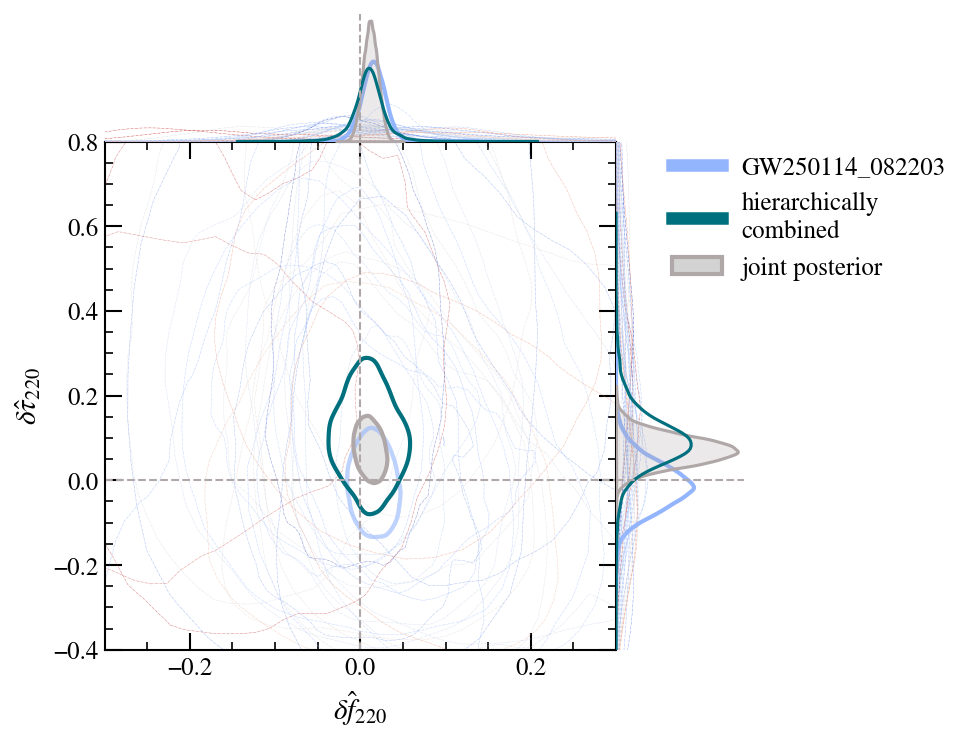

In [11]:
fig = plt.figure(figsize=(5.5, 5.5), dpi=200)
gs = fig.add_gridspec(ncols=2, nrows=2, width_ratios=[4, 1], height_ratios=[1, 4])

ax_joint = fig.add_subplot(gs[1, 0])
ax_df_220 = fig.add_subplot(gs[0, 0], sharex=ax_joint)
ax_dtau_220 = fig.add_subplot(gs[1, 1], sharey=ax_joint)
sns.despine(ax=ax_df_220)
sns.despine(ax=ax_dtau_220)
plt.subplots_adjust(hspace=0.0, wspace=0.0)

for event in event_list:

    c = cmap(norm(mtotal_dict[event]))

    if event in ["GW250114_082203"]:
        lw = 2.0
        matplotlib.rcParams["lines.linewidth"] = 2.0
        matplotlib.rcParams["patch.linewidth"] = 2.0
        if event == "GW250114_082203":
            ls = "solid"
    else:
        lw = 0.2
        matplotlib.rcParams["lines.linewidth"] = 0.2
        matplotlib.rcParams["patch.linewidth"] = 0.2
        ls = "dashdot"
        label = None

    sns.kdeplot(x=sample_dict["domega220"][event], ax=ax_df_220, lw=lw, color=c, ls=ls)
    sns.kdeplot(y=sample_dict["dtau220"][event], ax=ax_dtau_220, lw=lw, color=c, ls=ls)

    hist2d(
        ax=ax_joint,
        x=sample_dict["domega220"][event],
        y=sample_dict["dtau220"][event],
        color=c,
        quiet=True,
        bins=45,
        smooth=1.0,
        contour_kwargs={"linestyles": ls},
        no_fill_contours=True,
        **CORNER_KWARGS,
    )
    if event not in ["GW150914", "GW250114_082203"]:
        for collection in ax_joint.collections:
            if hasattr(collection, "set_alpha"):
                collection.set_alpha(0.2)

sns.kdeplot(
    x=domega220_comb, ax=ax_df_220, color="#b0a8a8", lw=1.5, fill=True, zorder=2, bw_adjust=1.2
)
sns.kdeplot(
    y=dtau220_comb, ax=ax_dtau_220, color="#b0a8a8", lw=1.5, fill=True, zorder=2
)

sns.kdeplot(x=domega220_hier, ax=ax_df_220, color="#00707e", lw=1.5)
sns.kdeplot(y=dtau220_hier, ax=ax_dtau_220, color="#00707e", lw=1.5)

lw = 2.0
matplotlib.rcParams["lines.linewidth"] = lw
matplotlib.rcParams["patch.linewidth"] = lw

sns.kdeplot(
    x=domega220_comb,
    y=dtau220_comb,
    levels=[0.1],
    color="#b0a8a8",
    ax=ax_joint,
    bw_adjust=1.5,
)
sns.kdeplot(
    x=domega220_hier,
    y=dtau220_hier,
    levels=[0.1],
    color="#00707e",
    ax=ax_joint,
    bw_adjust=1.5,
)

utils_o3b.kdeplot_2d_clevels_contourf(
    domega220_comb,
    dtau220_comb,
    levels=[0.90, 0.01],
    xlow=np.min(domega220_comb),
    xhigh=np.max(domega220_comb),
    ylow=np.min(dtau220_comb),
    yhigh=np.max(dtau220_comb),
    ax=ax_joint,
    linewidths=[0.1],
    colors=["k"],
    alpha=0.1,
)

df_220_min, df_220_max = -0.4, 0.4
dtau_220_min, dtau_220_max = -0.4, 0.8

tick_pos_x = np.linspace(df_220_min, df_220_max, num=5)
tick_pos_y = np.linspace(dtau_220_min, dtau_220_max, num=7)

ax_joint.set_xlabel(r"$\delta \hat{f}_{220}$", fontsize=14)
ax_joint.set_ylabel(r"$\delta \hat{\tau}_{220}$", fontsize=14)
ax_joint.set_xticks(tick_pos_x)
ax_joint.set_yticks(tick_pos_y)

ax_df_220.set_xlim(-0.3, 0.3)
ax_dtau_220.set_ylim(-0.4, 0.8)

linewidth = 1
ax_joint.xaxis.set_minor_locator(AutoMinorLocator())
ax_joint.yaxis.set_minor_locator(AutoMinorLocator())

tick_params = {
    "length": 4,
    "bottom": True,
    "left": True,
    "top": True,
    "right": True,
    "direction": "in",
    "zorder": 10,
}
major_tick_params = {**tick_params, "length": 8, "labelsize": 12}

for axis in ["x", "y"]:
    ax_joint.tick_params(axis=axis, which="minor", **tick_params)
    ax_joint.tick_params(axis=axis, which="major", **major_tick_params)

ax_joint.grid(visible=False)

ax_joint.axvline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_joint.axhline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_df_220.axvline(0, ls="--", c="#b0a8a8", linewidth=linewidth)
ax_dtau_220.axhline(0, ls="--", c="#b0a8a8", linewidth=linewidth)

ax_df_220.set_ylim(bottom=0.0)
ax_dtau_220.set_xlim(left=0.0)

ax_df_220.axis("off")
ax_dtau_220.axis("off")

ax_joint.legend(
    *ax_df_220.get_legend_handles_labels(),
    bbox_to_anchor=(-0.35, 1.0),  # Move legend outside to the left
    loc="upper left",
    frameon=False,
    prop={"size": 12},
    handlelength=3,
)


from matplotlib.lines import Line2D
from matplotlib.patches import Patch

c1 = cmap(norm(mtotal_dict["GW250114_082203"]))

custom_lines = [
    Line2D([0], [0], color=c1, lw=0.1, linestyle="-", label=r"GW250114_082203"),
    Line2D(
        [0],
        [0],
        color="#00707e",
        lw=0.1,
        linestyle="-",
        label="hierarchically\ncombined",
    ),
    Patch(facecolor="lightgray", edgecolor="#b0a8a8", label="joint posterior"),
]

ax_joint.legend(
    handles=custom_lines,
    loc="center left",
    bbox_to_anchor=(1.05, 0.85),
    frameon=False,
    prop={"size": 12},
    handlelength=2,
)

os.makedirs("./plots", exist_ok=True)
plt.savefig("./plots/rin_pseob_results.pdf", bbox_inches="tight")
plt.savefig("./plots/rin_pseob_results.png", bbox_inches="tight")

fig.set_dpi(150)
plt.show()

## Plot bounds

In [12]:
matplotlib.rcParams.update(matplotlib.rcParamsDefault)

matplotlib.style.use("paper.style")
plt.rcParams['font.sans-serif'] = [ 'Helvetica', 'Nimbus Sans', 'FreeSans' ]
plt.rcParams['font.serif'] = [ 'Times', 'Nimbus Roman', 'FreeSerif' ]
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'stix'

# further tune some rcParams
plt.rcParams.update(
    {
        "ytick.labelsize": 0.6 * utils_o3b.fs_label,
        "legend.fontsize": 0.8 * utils_o3b.fs_label,
    }
)

# Specify some aesthetic colours...
dodgerblue = "#1E90FF"
lawngreen = "#7CFC00"
blueviolet = "#8A2BE2"
caltechorange = "#FF6C0C"
walesaway = "#293133"
waleshome = "#ff0038"
uniwienblue = "#006699"
uniwiengrey = "#666666"
emeraldgreen = "#50C878"
tanzaniagreen = "#1eb53a"
grey3 = "#565759"
grey1 = "#C0BEC6"
grey2 = "#AAA7B0"

kwargs = {
    "GWTC-3 (Phenom)": {
        "markeredgewidth": 2,
        "markersize": 12,
        "alpha": 0.8,
        "marker": 6,
        "color": "0.6",
        "ls": "",
    },
    "GWTC-3 (SEOB)": {
        "markeredgewidth": 1,
        "markersize": 12,
        "alpha": 0.8,
        "marker": 6,
        "markeredgecolor": "#00707e",
        "markerfacecolor": "none",
        "ls": "",
    },
    "GWTC-2 (Phenom)": {
        "markeredgewidth": 2,
        "markersize": 12,
        "alpha": 0.8,
        "marker": 7,
        "color": "0.6",
        "ls": "",
    },
    "GWTC-2 (SEOB)": {
        "markeredgewidth": 1,
        "markersize": 12,
        "alpha": 0.8,
        "marker": 7,
        "markeredgecolor": "#00707e",
        "markerfacecolor": "none",
        "ls": "",
    },
    "GWTC-1 (Phenom)": {
        "markeredgewidth": 0.5,
        "markersize": 15,
        "marker": ".",
        "color": waleshome,
        "markeredgecolor": "w",
        "ls": "",
    },
    "GW170817 (Phenom)": {
        "markeredgewidth": 0.5,
        "markersize": 15,
        "marker": ".",
        "color": dodgerblue,
        "markeredgecolor": "w",
        "ls": "",
    },
    "event": {
        "marker": "_",
        "ls": "",
        "markersize": 20,
        "alpha": 0.5,
        "markeredgewidth": 3,
    },
    "GW150914": {
        "marker": "D",
        "ls": "",
        "markersize": 5,
        "alpha": 0.8,
        "markeredgewidth": 2,
        #'markerfacecolor': 'none',
    },
    "GW250114_082203": {
        "marker": "s",
        "ls": "",
        "markersize": 5,
        "alpha": 0.5,
        "markeredgewidth": 2,
        #'markerfacecolor': 'none',
    },
}

In [13]:
def kde_helper(samples, xlow=None, xhigh=None):
    # Initialize bounded KDE
    if xlow is None:
        xlow = np.amin(samples)
    if xhigh is None:
        xhigh = np.amax(samples)
    kde = Bounded_1d_kde(samples, xlow=xlow, xhigh=xhigh)
    pts = np.linspace(xlow, xhigh, num=500)
    pdf = kde(pts)

    return pts, pdf

In [14]:
df_220_comb_pts, df_220_comb_pdf = kde_helper(domega220_comb)
dtau_220_comb_pts, dtau_220_comb_pdf = kde_helper(dtau220_comb)
df_220_hier_pts, df_220_hier_pdf = kde_helper(domega220_hier)
dtau_220_hier_pts, dtau_220_hier_pdf = kde_helper(dtau220_hier)

/home/lorenzo.pompili/.conda/envs/igwn-tgr-data-release/lib/python3.10/site-packages/pesummary/utils/decorators.py:288: UserWarning: pesummary.core.plots.bounded_1d_kde.bounded_1d_kde has changed to pesummary.utils.bounded_1d_kde.bounded_1d_kde. This may not be supported in future releases. Please update.
  warnings.warn(warning)


Event 	 Total Mass 	 CI:domega220 	 CI:dtau220


GW150914 	 71 	 0.17 	 0.64
GW170104 	 60 	 0.30 	 1.62
S190519bj 	 155 	 0.33 	 0.96
S190521r 	 93 	 0.29 	 0.66
S190630ag 	 70 	 0.33 	 1.09
S190828j 	 80 	 0.26 	 1.05
S190910s 	 102 	 0.23 	 1.14
S200129m 	 75 	 0.14 	 0.67
S200224ca 	 95 	 0.27 	 0.83
S200311bg 	 76 	 0.26 	 1.94
S230628ax 	 62 	 0.28 	 0.87
S230914ak 	 96 	 0.26 	 0.88
S230927be 	 39 	 0.16 	 0.89
S231028bg 	 151 	 0.30 	 0.60
S231102w 	 105 	 0.61 	 0.80
S231206cc 	 66 	 0.21 	 0.65
S231226av 	 74 	 0.22 	 0.45
GW240511_031507 	 99 	 0.26 	 0.75
GW240514_121713 	 120 	 0.31 	 0.68
GW240615_113620 	 78 	 0.19 	 0.52
GW240621_195059 	 81 	 0.18 	 0.55
GW240705_053215 	 132 	 0.38 	 0.69
GW240716_034900 	 90 	 0.31 	 0.97
GW240919_061559 	 91 	 0.24 	 0.81
GW240920_124024 	 83 	 0.10 	 0.46
GW241006_015333 	 60 	 0.42 	 0.89
GW241127_061008 	 104 	 0.27 	 0.78
GW241129_021832 	 77 	 0.29 	 0.80
GW241225_082815 	 132 	 0.32 	 0.93
GW250114_082203 	 72 	 0.05 	 0.19
GW250119_025138 	 91 	 0.33 	 1.11
Joint lklhd 	 --

/local/leonardo.grimaldi/ipykernel_237299/3757178612.py:148: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  cbar = plt.colorbar(sm, ticks=np.arange(45, 165, 10))


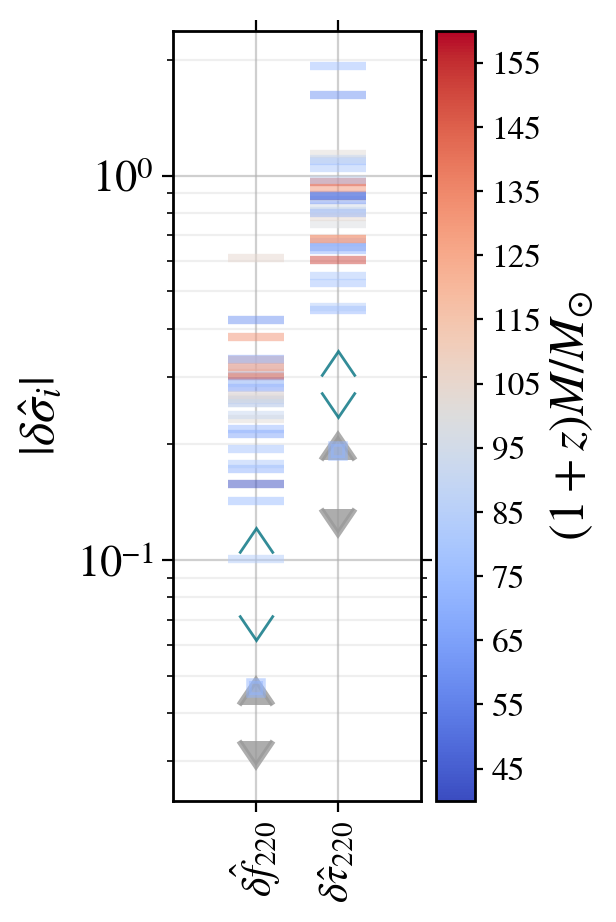

In [15]:
print(f"Event \t Total Mass \t CI:domega220 \t CI:dtau220")

fig = plt.figure(figsize=(2, 5), dpi=200)
ax = fig.add_subplot(111)

for event in event_list:

    domega220_pts, domega220_pdf = kde_helper(
        sample_dict["domega220"][event],
        xlow=prior_dict["domega_220-min"][event],
        xhigh=prior_dict["domega_220-max"][event],
    )
    dtau220_pts, dtau220_pdf = kde_helper(
        sample_dict["dtau220"][event],
        xlow=prior_dict["dtau_220-min"][event],
        xhigh=prior_dict["dtau_220-max"][event],
    )

    domega220_left, domega220_right = utils_o3b.get_sym_interval_from_pdf(
        domega220_pdf, domega220_pts, p=0.9, normalize=True
    )
    dtau220_left, dtau220_right = utils_o3b.get_sym_interval_from_pdf(
        dtau220_pdf, dtau220_pts, p=0.9, normalize=True
    )

    c = cmap(norm(mtotal_dict[event]))

    print(
        f"{event} \t {mtotal_dict[event]} \t {domega220_right - domega220_left:.2f} \t {dtau220_right - dtau220_left:.2f}"
    )

    if event == "GW250114_082203":
        ax.semilogy(0, domega220_right - domega220_left, c=c, zorder=3, **kwargs["GW250114_082203"])
        ax.semilogy(1, dtau220_right - dtau220_left, c=c, zorder=3, **kwargs["GW250114_082203"])
    else:
        ax.semilogy(0, domega220_right - domega220_left, c=c, **kwargs["event"])
        ax.semilogy(1, dtau220_right - dtau220_left, c=c, **kwargs["event"])


# condifence intervals on combined posteriors
domega220_comb_left, domega220_comb_right = utils_o3b.get_sym_interval_from_pdf(
    df_220_comb_pdf, df_220_comb_pts, p=0.9, normalize=True
)
dtau220_comb_left, dtau220_comb_right = utils_o3b.get_sym_interval_from_pdf(
    dtau_220_comb_pdf, dtau_220_comb_pts, p=0.9, normalize=True
)
ax.semilogy(
    0,
    domega220_comb_right - domega220_comb_left,
    **kwargs["GWTC-2 (Phenom)"],
    label="joint\nlikelihood",
)
ax.semilogy(1, dtau220_comb_right - dtau220_comb_left, **kwargs["GWTC-2 (Phenom)"])

print(
    f"Joint lklhd \t -- \t {domega220_comb_right - domega220_comb_left:.2f} \t {dtau220_comb_right - dtau220_comb_left:.2f}"
)

# condifence intervals on hierarchical posteriors
domega220_hier_left, domega220_hier_right = utils_o3b.get_sym_interval_from_pdf(
    df_220_hier_pdf, df_220_hier_pts, p=0.9, normalize=True
)
dtau220_hier_left, dtau220_hier_right = utils_o3b.get_sym_interval_from_pdf(
    dtau_220_hier_pdf, dtau_220_hier_pts, p=0.9, normalize=True
)
ax.semilogy(
    0,
    domega220_hier_right - domega220_hier_left,
    **kwargs["GWTC-2 (SEOB)"],
    label="hierarchically\ncombined",
)
ax.semilogy(1, dtau220_hier_right - dtau220_hier_left, **kwargs["GWTC-2 (SEOB)"])

print(
    f"Hier \t -- \t {domega220_hier_right - domega220_hier_left:.2f} \t {dtau220_hier_right - dtau220_hier_left:.2f}"
)


# domega_220
df_220_comb_pts_O4a, df_220_comb_pdf_O4a = kde_helper(domega220_comb_O4a)
# dtau_220
dtau_220_comb_pts_O4a, dtau_220_comb_pdf_O4a = kde_helper(dtau220_comb_O4a)

# condifence intervals on combined posteriors
domega220_comb_left_O4a, domega220_comb_right_O4a = utils_o3b.get_sym_interval_from_pdf(
    df_220_comb_pdf_O4a, df_220_comb_pts_O4a, p=0.9, normalize=True
)
dtau220_comb_left_O4a, dtau220_comb_right_O4a = utils_o3b.get_sym_interval_from_pdf(
    dtau_220_comb_pdf_O4a, dtau_220_comb_pts_O4a, p=0.9, normalize=True
)
ax.semilogy(
    0,
    domega220_comb_right_O4a - domega220_comb_left_O4a,
    **kwargs["GWTC-3 (Phenom)"],
    label="joint\nlikelihood",
)
ax.semilogy(
    1, dtau220_comb_right_O4a - dtau220_comb_left_O4a, **kwargs["GWTC-3 (Phenom)"]
)

print(
    f"Joint lklhd (O4a) \t -- \t {domega220_comb_right_O4a - domega220_comb_left_O4a:.2f} \t {dtau220_comb_right_O4a - dtau220_comb_left_O4a:.2f}"
)

# Plot the hierarchical results
# domega_220
df_220_hier_pts_O4a, df_220_hier_pdf_O4a = kde_helper(domega220_hier_O4a)
# dtau_220
dtau_220_hier_pts_O4a, dtau_220_hier_pdf_O4a = kde_helper(dtau220_hier_O4a)

domega220_hier_left_O4a, domega220_hier_right_O4a = utils_o3b.get_sym_interval_from_pdf(
    df_220_hier_pdf_O4a, df_220_hier_pts_O4a, p=0.9, normalize=True
)
dtau220_hier_left_O4a, dtau220_hier_right_O4a = utils_o3b.get_sym_interval_from_pdf(
    dtau_220_hier_pdf_O4a, dtau_220_hier_pts_O4a, p=0.9, normalize=True
)
ax.semilogy(
    0,
    domega220_hier_right_O4a - domega220_hier_left_O4a,
    **kwargs["GWTC-3 (SEOB)"],
    label="hierarchically\ncombined",
)
ax.semilogy(
    1, dtau220_hier_right_O4a - dtau220_hier_left_O4a, **kwargs["GWTC-3 (SEOB)"]
)

print(
    f"Hier (O4a) \t -- \t {domega220_hier_right_O4a - domega220_hier_left_O4a:.2f} \t {dtau220_hier_right_O4a - dtau220_hier_left_O4a:.2f}"
)


ax.set_xticks(np.arange(len(params)))
ax.set_xticklabels(
    [r"$\delta \hat{f}_{220}$", r"$\delta \hat{\tau}_{220}$"], fontsize=15, rotation=90
)
ax.tick_params(axis="y", labelsize=16)
ax.tick_params(axis="x", which="minor", bottom=False, top=False)
ax.set_ylabel("$|\delta \hat{\sigma}_i|$", fontsize=18)
ax.grid(which="major", axis="both", linestyle="-", alpha=0.6)
ax.grid(which="minor", linestyle="-", alpha=0.2, axis="y")

# Set x- and y-limits
ax.set_xlim(-1.0, 2.0)

# add colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ticks=np.arange(45, 165, 10))
cbar.ax.set_yticklabels(cbar.ax.get_yticklabels(), fontsize=12)
cbar.ax.tick_params("y", length=3, which="major")
cbar.ax.tick_params("y", which="minor", left=False, right=False)
cbar.set_label(r"$ (1 + z) M / M_{\odot}$", fontsize=18, labelpad=2.5)

plt.savefig(
    "./plots/rin_all_events_bounds_fix.pdf",
    bbox_inches="tight",
)
plt.savefig(
    "./plots/rin_all_events_bounds_fix.png",
    bbox_inches="tight",
)
plt.show()